# 01 · Citi Bike NYC — EDA, limpieza y preparación de datos

**Objetivo del proyecto:** predecir, para cada estación y cada intervalo de 15 minutos, cuántas bicis **salen** y cuántas **llegan**, separadas por tipo (`classic_bike` / `electric_bike`).

**Este notebook:**
1. Carga todos los CSVs de las carpetas `AAAAMM-citibike-tripdata/`.
2. Diagnostica y **elimina toda fila con algún null o campo vacío**.
3. Limpia registros inválidos (duplicados, duraciones imposibles, coordenadas fuera de NYC, estaciones de prueba).
4. Redondea los tiempos **hacia abajo** a slots de 15 minutos (16:13 → 16:00), es decir, 96 slots por día.
5. Construye la tabla de demanda `estación × slot` con 4 objetivos: `salidas_classic`, `salidas_electric`, `llegadas_classic`, `llegadas_electric`.
6. Descarga el clima histórico de **Open-Meteo** y crea las variables de calendario (día de semana, fin de semana, festivos).
7. EDA visual con seaborn: tendencias, horas pico, estaciones que se vacían o se llenan, impacto del clima y correlaciones.
8. Exporta los archivos `.parquet` que consume el notebook 02 (PyTorch).

**Salidas** (en `data_procesada/`): `estaciones.parquet`, `slots.parquet` (calendario + clima por slot) y `demanda_15min.parquet` (objetivos por estación y slot).

> Requisitos: `pip install pandas pyarrow numpy matplotlib seaborn requests` y, opcionalmente, `holidays`.

## 0. Aceleración opcional con GPU (RAPIDS `cudf.pandas`)
Si tienes RAPIDS instalado (Linux o WSL2 con GPU NVIDIA), `cudf.pandas` acelera pandas en la GPU **sin cambiar el código**. Si no está instalado, el notebook sigue funcionando con pandas normal. Esta celda **debe ejecutarse antes** de importar pandas.

In [2]:
USAR_CUDF = False   # cambia a True si tienes RAPIDS (pip install cudf-cu12 ...)

if USAR_CUDF:
    try:
        get_ipython().run_line_magic('load_ext', 'cudf.pandas')
        print('✅ cudf.pandas activado: pandas se ejecutará en GPU cuando sea posible')
    except Exception as e:
        print('⚠️ cudf.pandas no disponible, se usará pandas en CPU:', e)

## 1. Imports y configuración

In [3]:
import re
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import requests

warnings.filterwarnings('ignore', category=FutureWarning)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (13, 5)
plt.rcParams['figure.dpi'] = 100
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)

print('pandas', pd.__version__, '| numpy', np.__version__, '| seaborn', sns.__version__)

pandas 3.0.6 | numpy 2.5.3 | seaborn 0.13.2


In [4]:
# ───────────────────────── CONFIGURACIÓN ─────────────────────────
DATA_DIR   = Path('.')                      # carpeta que CONTIENE las carpetas 2026MM-citibike-tripdata/
PATRON_CSV = '*-citibike-tripdata/*-citibike-tripdata_*.csv'
OUT_DIR    = Path('data_procesada')
OUT_DIR.mkdir(parents=True, exist_ok=True)

FREQ       = '15min'                        # tamaño del slot
SLOTS_DIA  = 96                             # 24 h × 4
TZ         = 'America/New_York'             # Citi Bike reporta hora local de NYC
NYC_LAT, NYC_LON = 40.7128, -74.0060        # punto para el clima (nivel ciudad)

# Caja geográfica amplia de NYC (descarta coordenadas corruptas)
BBOX = dict(lat_min=40.45, lat_max=41.00, lng_min=-74.30, lng_max=-73.65)

MIN_DURACION_S      = 60      # viajes < 60 s que vuelven a la misma estación = re-anclajes, no viajes
MAX_DURACION_H      = 24      # viajes > 24 h = bicis perdidas o errores
MIN_VIAJES_ESTACION = 100     # estaciones con menos actividad total (salidas+llegadas) en el periodo se descartan
TIPOS_BICI          = ['classic_bike', 'electric_bike']

# Estaciones de taller, laboratorio o prueba (no son demanda real)
PATRON_ESTACIONES_PRUEBA = r'(?:\btest\b|lab - nyc|workshop|\bmobile\b|nycbs depot|warehouse|\bdepot\b)'

# Variables de clima a descargar (Open-Meteo, por hora)
VARS_CLIMA = ['temperature_2m', 'apparent_temperature', 'relative_humidity_2m',
              'precipitation', 'rain', 'snowfall', 'cloud_cover',
              'wind_speed_10m', 'weather_code']
CLIMA_CACHE = OUT_DIR / 'clima_horario_raw.parquet'

## 2. Localizar los archivos

In [5]:
archivos = sorted(DATA_DIR.glob(PATRON_CSV))
assert archivos, f'No se encontraron CSVs con el patrón {PATRON_CSV} dentro de {DATA_DIR.resolve()}'

meses = sorted({re.search(r'(\d{6})-citibike', f.name).group(1) for f in archivos})
INICIO = pd.Timestamp(f'{meses[0][:4]}-{meses[0][4:]}-01')
FIN    = pd.Timestamp(f'{meses[-1][:4]}-{meses[-1][4:]}-01') + pd.offsets.MonthBegin(1)   # exclusivo

print(f'{len(archivos)} archivos | meses: {meses}')
print(f'Periodo de análisis: {INICIO:%Y-%m-%d} → {FIN - pd.Timedelta(minutes=15):%Y-%m-%d %H:%M}')
tam_total = 0
for f in archivos:
    tam = f.stat().st_size / 1e6
    tam_total += tam
    print(f'  {f}  ({tam:,.0f} MB)')
print(f'Total: {tam_total:,.0f} MB')

16 archivos | meses: ['202607', '202608', '202609']
Periodo de análisis: 2026-07-01 → 2026-09-30 23:45
  202607-citibike-tripdata/202607-citibike-tripdata_1.csv  (195 MB)
  202607-citibike-tripdata/202607-citibike-tripdata_2.csv  (195 MB)
  202607-citibike-tripdata/202607-citibike-tripdata_3.csv  (195 MB)
  202607-citibike-tripdata/202607-citibike-tripdata_4.csv  (195 MB)
  202607-citibike-tripdata/202607-citibike-tripdata_5.csv  (194 MB)
  202608-citibike-tripdata/202608-citibike-tripdata_1.csv  (195 MB)
  202608-citibike-tripdata/202608-citibike-tripdata_2.csv  (195 MB)
  202608-citibike-tripdata/202608-citibike-tripdata_3.csv  (195 MB)
  202608-citibike-tripdata/202608-citibike-tripdata_4.csv  (195 MB)
  202608-citibike-tripdata/202608-citibike-tripdata_5.csv  (195 MB)
  202608-citibike-tripdata/202608-citibike-tripdata_6.csv  (48 MB)
  202609-citibike-tripdata/202609-citibike-tripdata_1.csv  (195 MB)
  202609-citibike-tripdata/202609-citibike-tripdata_2.csv  (195 MB)
  202609-citib

## 3. Carga, diagnóstico de nulls y eliminación
Se procesa **archivo por archivo** para ahorrar memoria. Los textos vacíos o con sólo espacios se convierten en null; después se registra cuántos nulls hay por columna y **se elimina cualquier fila con al menos un null**. También se registra qué tipo de bici se pierde más, porque las e-bikes que terminan fuera de un dock suelen venir sin estación final.

In [6]:
STR = 'string[pyarrow]'
COLUMNAS = ['ride_id', 'rideable_type', 'started_at', 'ended_at',
            'start_station_name', 'start_station_id', 'end_station_name', 'end_station_id',
            'start_lat', 'start_lng', 'end_lat', 'end_lng', 'member_casual']
COLS_TEXTO = ['ride_id', 'rideable_type', 'started_at', 'ended_at', 'start_station_name',
              'start_station_id', 'end_station_name', 'end_station_id', 'member_casual']
DTYPES = {c: STR for c in COLS_TEXTO}
DTYPES.update({c: 'float64' for c in ['start_lat', 'start_lng', 'end_lat', 'end_lng']})

reporte_nulos, perdidas_tipo, partes = [], [], []
t_total = time.time()

for f in archivos:
    t0 = time.time()
    d = pd.read_csv(f, usecols=COLUMNAS, dtype=DTYPES)
    n0 = len(d)

    # textos vacíos o con espacios → null
    for c in COLS_TEXTO:
        d[c] = d[c].str.strip().replace('', pd.NA)

    # fechas: lo que no se pueda parsear también cuenta como null
    for c in ['started_at', 'ended_at']:
        d[c] = pd.to_datetime(d[c], format='ISO8601', errors='coerce')

    nulos = d.isna().sum()
    fila_con_nulo = d.isna().any(axis=1)
    reporte_nulos.append({'archivo': f.name, 'filas': n0, 'filas_con_null': int(fila_con_nulo.sum()),
                          **nulos.to_dict()})
    tipos_tot = d['rideable_type'].value_counts(dropna=False)
    tipos_nul = d.loc[fila_con_nulo, 'rideable_type'].value_counts(dropna=False)
    perdidas_tipo.append(pd.DataFrame({'total': tipos_tot, 'con_null': tipos_nul}).fillna(0))

    d = d.loc[~fila_con_nulo].copy()
    for c in ['rideable_type', 'member_casual']:
        d[c] = d[c].astype('category')
    partes.append(d)
    print(f'{f.name}: {n0:>10,} filas → {len(d):>10,} sin nulls  ({time.time() - t0:.1f}s)')

df = pd.concat(partes, ignore_index=True)
del partes
for c in ['rideable_type', 'member_casual', 'start_station_id', 'end_station_id',
          'start_station_name', 'end_station_name']:
    df[c] = df[c].astype('category')

rep = pd.DataFrame(reporte_nulos)
FILAS_ORIGINALES = int(rep['filas'].sum())
print(f'\nTotal original: {FILAS_ORIGINALES:,} | sin nulls: {len(df):,} '
      f'({len(df) / FILAS_ORIGINALES:.1%}) | {time.time() - t_total:.0f}s')
print(f'Memoria del DataFrame: {df.memory_usage(deep=True).sum() / 1e9:.2f} GB')

202607-citibike-tripdata_1.csv:  1,000,000 filas →    998,560 sin nulls  (2.5s)
202607-citibike-tripdata_2.csv:  1,000,000 filas →    993,923 sin nulls  (2.2s)
202607-citibike-tripdata_3.csv:  1,000,000 filas →    998,130 sin nulls  (1.9s)
202607-citibike-tripdata_4.csv:  1,000,000 filas →    993,133 sin nulls  (4.9s)
202607-citibike-tripdata_5.csv:    993,137 filas →    991,661 sin nulls  (1.9s)
202608-citibike-tripdata_1.csv:  1,000,000 filas →    999,245 sin nulls  (2.3s)
202608-citibike-tripdata_2.csv:  1,000,000 filas →    999,376 sin nulls  (2.5s)
202608-citibike-tripdata_3.csv:  1,000,000 filas →    992,480 sin nulls  (2.4s)
202608-citibike-tripdata_4.csv:  1,000,000 filas →    994,443 sin nulls  (2.3s)
202608-citibike-tripdata_5.csv:  1,000,000 filas →    997,427 sin nulls  (2.1s)
202608-citibike-tripdata_6.csv:    246,236 filas →    246,109 sin nulls  (0.5s)
202609-citibike-tripdata_1.csv:  1,000,000 filas →    997,311 sin nulls  (1.8s)
202609-citibike-tripdata_2.csv:  1,000,0

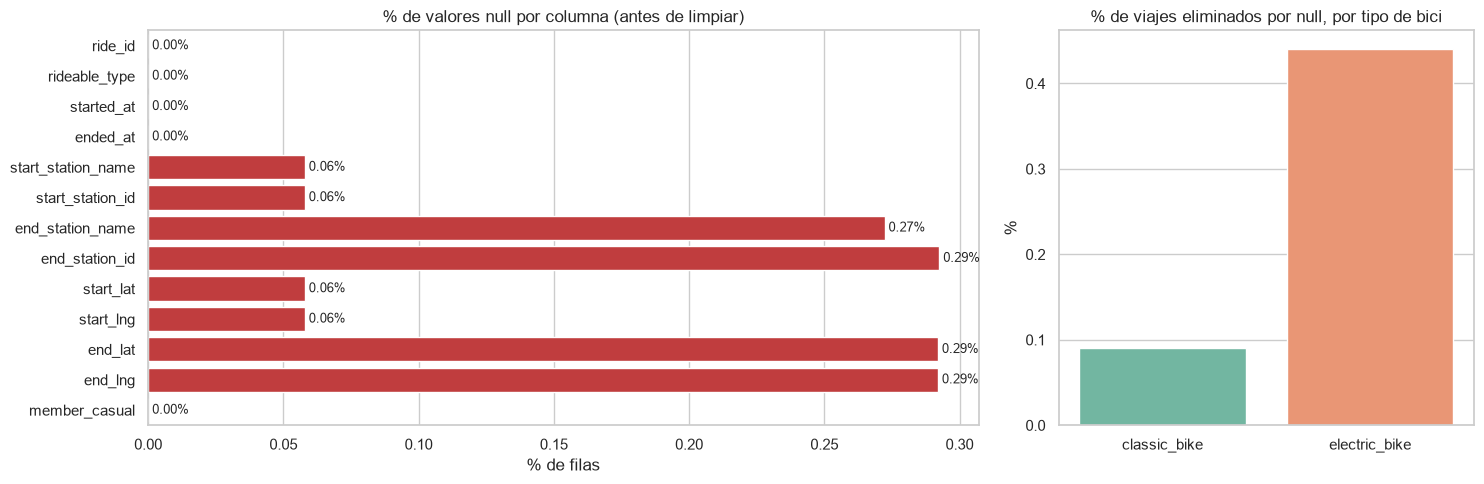

,filas,filas_con_null,pct
archivo,,,
202607-citibike-tripdata_1.csv,1000000,1440,0.14
202607-citibike-tripdata_2.csv,1000000,6077,0.61
202607-citibike-tripdata_3.csv,1000000,1870,0.19
202607-citibike-tripdata_4.csv,1000000,6867,0.69
202607-citibike-tripdata_5.csv,993137,1476,0.15
202608-citibike-tripdata_1.csv,1000000,755,0.08
202608-citibike-tripdata_2.csv,1000000,624,0.06
202608-citibike-tripdata_3.csv,1000000,7520,0.75
202608-citibike-tripdata_4.csv,1000000,5557,0.56


,total,con_null,% perdido
rideable_type,,,
classic_bike,4099267,3543,0.09
electric_bike,11122961,48507,0.44


In [10]:
# ── Visualización del diagnóstico de nulls ──
nul_col = rep[COLUMNAS].sum() / FILAS_ORIGINALES * 100
perd = pd.concat(perdidas_tipo).groupby(level=0, dropna=False).sum().astype(int)
perd['% perdido'] = (perd['con_null'] / perd['total'] * 100).round(2)

fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={'width_ratios': [2, 1]})
sns.barplot(x=nul_col.values, y=nul_col.index, ax=axes[0], color='tab:red')
axes[0].set(title='% de valores null por columna (antes de limpiar)', xlabel='% de filas', ylabel='')
for i, v in enumerate(nul_col.values):
    axes[0].text(v, i, f' {v:.2f}%', va='center', fontsize=9)

perd_plot = perd.reset_index().rename(columns={'index': 'tipo', 'rideable_type': 'tipo'})
sns.barplot(data=perd_plot, x='tipo', y='% perdido', ax=axes[1], palette='Set2', hue='tipo', legend=False)
axes[1].set(title='% de viajes eliminados por null, por tipo de bici', xlabel='', ylabel='%')
plt.tight_layout(); plt.show()

display(rep.set_index('archivo')[['filas', 'filas_con_null']].assign(
    pct=lambda x: (x.filas_con_null / x.filas * 100).round(2)))
display(perd)

## 4. Limpieza de registros inválidos
Cada paso queda registrado en una bitácora para saber exactamente cuántas filas elimina.

In [12]:
bitacora = [('Original (todas las filas)', FILAS_ORIGINALES), ('Sin nulls ni vacíos', len(df))]
def registrar(paso):
    bitacora.append((paso, len(df)))
    print(f'{paso:<55} → {len(df):>12,} filas')

# 4.1 duplicados de ride_id
df = df.drop_duplicates(subset='ride_id', keep='first'); registrar('Sin ride_id duplicados')

# 4.2 sólo tipos de bici válidos
print('Tipos encontrados:', df['rideable_type'].value_counts().to_dict())
df = df[df['rideable_type'].isin(TIPOS_BICI)]
df['rideable_type'] = df['rideable_type'].cat.remove_unused_categories()
registrar('Sólo classic_bike / electric_bike')

# 4.3 duración válida
df['duracion_s'] = (df['ended_at'] - df['started_at']).dt.total_seconds()
df = df[df['duracion_s'] > 0]; registrar('ended_at > started_at')
df = df[df['duracion_s'] <= MAX_DURACION_H * 3600]; registrar(f'Duración ≤ {MAX_DURACION_H} h')

# 4.4 coordenadas dentro de NYC
dentro = (df['start_lat'].between(BBOX['lat_min'], BBOX['lat_max']) &
          df['end_lat'].between(BBOX['lat_min'], BBOX['lat_max']) &
          df['start_lng'].between(BBOX['lng_min'], BBOX['lng_max']) &
          df['end_lng'].between(BBOX['lng_min'], BBOX['lng_max']))
df = df[dentro]; registrar('Coordenadas dentro de NYC')

# 4.5 estaciones de prueba / taller
prueba = (df['start_station_name'].astype(str).str.contains(PATRON_ESTACIONES_PRUEBA, case=False, regex=True) |
          df['end_station_name'].astype(str).str.contains(PATRON_ESTACIONES_PRUEBA, case=False, regex=True))
todos_nombres = pd.Series(sorted(set(df['start_station_name'].astype(str)) | set(df['end_station_name'].astype(str))))
print('Estaciones de prueba detectadas:',
      todos_nombres[todos_nombres.str.contains(PATRON_ESTACIONES_PRUEBA, case=False, regex=True)].tolist())
df = df[~prueba]; registrar('Sin estaciones de prueba / taller')

# 4.6 viajes que inician dentro del periodo
df = df[(df['started_at'] >= INICIO) & (df['started_at'] < FIN)]; registrar('Inicio dentro del periodo')

for c in ['start_station_id', 'end_station_id', 'start_station_name', 'end_station_name']:
    df[c] = df[c].cat.remove_unused_categories()
df = df.reset_index(drop=True)

Sin ride_id duplicados                                  →   15,170,092 filas
Tipos encontrados: {'electric_bike': 11074454, 'classic_bike': 4095638}
Sólo classic_bike / electric_bike                       →   15,170,092 filas
ended_at > started_at                                   →   15,170,092 filas
Duración ≤ 24 h                                         →   15,170,092 filas
Coordenadas dentro de NYC                               →   15,170,092 filas
Estaciones de prueba detectadas: []
Sin estaciones de prueba / taller                       →   15,170,092 filas
Inicio dentro del periodo                               →   15,169,280 filas


## 5. Redondeo a slots de 15 minutos (siempre hacia abajo)

In [13]:
df['slot_salida']  = df['started_at'].dt.floor(FREQ)
df['slot_llegada'] = df['ended_at'].dt.floor(FREQ)

muestra = df[['started_at', 'slot_salida', 'ended_at', 'slot_llegada']].sample(6, random_state=1)
display(muestra)
assert (df['slot_salida'].dt.minute % 15 == 0).all() and (df['slot_salida'] <= df['started_at']).all()
print('✅ Todos los tiempos quedaron en x:00, x:15, x:30 o x:45, redondeados hacia abajo')

,started_at,slot_salida,ended_at,slot_llegada
15156408,2026-09-21 17:58:27.009,2026-09-21 17:45:00,2026-09-21 18:16:21.961,2026-09-21 18:15:00
13738034,2026-09-21 15:41:25.378,2026-09-21 15:30:00,2026-09-21 15:56:10.462,2026-09-21 15:45:00
12566955,2026-09-12 00:50:44.610,2026-09-12 00:45:00,2026-09-12 01:02:47.986,2026-09-12 01:00:00
14150164,2026-09-21 07:53:09.534,2026-09-21 07:45:00,2026-09-21 08:29:41.634,2026-09-21 08:15:00
12605034,2026-09-30 15:00:01.802,2026-09-30 15:00:00,2026-09-30 15:21:04.008,2026-09-30 15:15:00
5561799,2026-08-03 17:30:53.395,2026-08-03 17:30:00,2026-08-03 17:37:35.179,2026-08-03 17:30:00


✅ Todos los tiempos quedaron en x:00, x:15, x:30 o x:45, redondeados hacia abajo


## 6. Catálogo de estaciones
Un mismo `station_id` puede aparecer con nombres o coordenadas ligeramente distintos (las e-bikes reportan GPS). Se usa el nombre más frecuente y la **mediana** de las coordenadas. Después se filtran las estaciones con muy poca actividad.

In [14]:
ini = df[['start_station_id', 'start_station_name', 'start_lat', 'start_lng']].set_axis(['station_id', 'name', 'lat', 'lng'], axis=1)
fin = df[['end_station_id', 'end_station_name', 'end_lat', 'end_lng']].set_axis(['station_id', 'name', 'lat', 'lng'], axis=1)
for t in (ini, fin):
    t['station_id'] = t['station_id'].astype(str); t['name'] = t['name'].astype(str)
puntos = pd.concat([ini, fin], ignore_index=True)

nombres = (puntos.groupby(['station_id', 'name']).size().rename('n').reset_index()
           .sort_values('n', ascending=False).drop_duplicates('station_id').set_index('station_id')['name'])
coords = puntos.groupby('station_id')[['lat', 'lng']].median()
salidas_tot  = df['start_station_id'].astype(str).value_counts()
llegadas_tot = df['end_station_id'].astype(str).value_counts()
del ini, fin, puntos

estaciones = coords.join(nombres)
estaciones['salidas_total']  = salidas_tot.reindex(estaciones.index).fillna(0).astype(int)
estaciones['llegadas_total'] = llegadas_tot.reindex(estaciones.index).fillna(0).astype(int)
estaciones['actividad_total'] = estaciones['salidas_total'] + estaciones['llegadas_total']

n_antes = len(estaciones)
estaciones = estaciones[estaciones['actividad_total'] >= MIN_VIAJES_ESTACION].copy()
print(f'Estaciones encontradas: {n_antes:,} | con ≥ {MIN_VIAJES_ESTACION} viajes: {len(estaciones):,}')

estaciones = estaciones.sort_values('actividad_total', ascending=False).reset_index()
estaciones['station_idx'] = np.arange(len(estaciones), dtype=np.int32)
display(estaciones.head(10))

Estaciones encontradas: 2,572 | con ≥ 100 viajes: 2,461


,station_id,lat,lng,name,salidas_total,llegadas_total,actividad_total,station_idx
0,6233.04,40.746872,-74.008210,Pier 61 at Chelsea Piers,51779,51843,103622,0
1,6140.05,40.741740,-73.994156,W 21 St & 6 Ave,51662,51844,103506,1
2,6331.01,40.749156,-73.991600,W 31 St & 7 Ave,45151,44962,90113,2
3,6492.08,40.752568,-73.996765,9 Ave & W 33 St,44215,44428,88643,3
4,6948.10,40.766953,-73.981693,Broadway & W 58 St,43083,42899,85982,4
5,5905.12,40.734546,-73.990741,Broadway & E 14 St,42861,42766,85627,5
6,5905.14,40.734814,-73.992085,University Pl & E 14 St,41215,41405,82620,6
7,6876.04,40.765909,-73.976342,Central Park S & 6 Ave,40913,40539,81452,7
8,6432.09,40.751873,-73.977706,Park Ave & E 42 St,40184,40564,80748,8
9,6726.01,40.760301,-73.998842,11 Ave & W 41 St,39963,39870,79833,9


## 7. Matriz de demanda `estación × slot × objetivo`
Se cuenta con `np.bincount` sobre un arreglo denso de forma `[n_estaciones, n_slots, 4]`, que es mucho más rápido y ligero que hacer pivot sobre millones de filas.

Además, cada estación sólo se considera **desde el primer día hasta el último día en que tuvo actividad**. Así, las estaciones inauguradas o retiradas a mitad del periodo no llenan el entrenamiento de ceros falsos.

In [15]:
TARGETS = ['salidas_classic', 'salidas_electric', 'llegadas_classic', 'llegadas_electric']
slots_ts = pd.date_range(INICIO, FIN, freq=FREQ, inclusive='left')
N_SLOTS, N_EST = len(slots_ts), len(estaciones)
mapa_est = pd.Series(estaciones['station_idx'].values, index=estaciones['station_id'].values)
tipo_idx = df['rideable_type'].map({'classic_bike': 0, 'electric_bike': 1}).astype(np.int64).values
paso = pd.Timedelta(FREQ)

def indices(col_est, col_slot, canal_base):
    s = df[col_est].astype(str).map(mapa_est)
    t = ((df[col_slot] - INICIO) // paso).astype('int64')
    ok = s.notna().values & (t.values >= 0) & (t.values < N_SLOTS)
    s = s.values[ok].astype(np.int64); t = t.values[ok]
    c = canal_base + tipo_idx[ok]
    return (s * N_SLOTS + t) * 4 + c, ok

flat_sal, ok_sal = indices('start_station_id', 'slot_salida', 0)
flat_lle, ok_lle = indices('end_station_id', 'slot_llegada', 2)
Y = np.bincount(np.concatenate([flat_sal, flat_lle]), minlength=N_EST * N_SLOTS * 4)
Y = Y.reshape(N_EST, N_SLOTS, 4).astype(np.int16)
print(f'Salidas usadas: {ok_sal.sum():,} | llegadas usadas: {ok_lle.sum():,} '
      f'(las llegadas fuera del periodo o a estaciones descartadas no se cuentan)')
print(f'Matriz Y: {Y.shape}  ({Y.nbytes / 1e6:.0f} MB)')

# ventana activa por estación (días completos)
actividad = Y.sum(axis=2) > 0                         # [est, slot]
primero = actividad.argmax(axis=1)
ultimo  = N_SLOTS - 1 - actividad[:, ::-1].argmax(axis=1)
primer_slot = (primero // SLOTS_DIA) * SLOTS_DIA
ultimo_slot = (ultimo // SLOTS_DIA + 1) * SLOTS_DIA   # exclusivo
rango = np.arange(N_SLOTS)
mascara_activa = (rango[None, :] >= primer_slot[:, None]) & (rango[None, :] < ultimo_slot[:, None])
estaciones['primer_dia'] = slots_ts[primer_slot].normalize()
estaciones['ultimo_dia'] = slots_ts[ultimo_slot - 1].normalize()
estaciones['dias_activa'] = (ultimo_slot - primer_slot) // SLOTS_DIA
print(f'Estaciones activas todo el periodo: {(estaciones.dias_activa == N_SLOTS // SLOTS_DIA).sum():,} de {N_EST:,}')

Salidas usadas: 15,168,766 | llegadas usadas: 15,167,313 (las llegadas fuera del periodo o a estaciones descartadas no se cuentan)
Matriz Y: (2461, 8832, 4)  (174 MB)
Estaciones activas todo el periodo: 2,209 de 2,461


In [16]:
# Tabla larga para el modelo: una fila por (estación, slot) dentro de su ventana activa
s_idx, t_idx = np.nonzero(mascara_activa)
demanda = pd.DataFrame({'station_idx': s_idx.astype(np.int32), 'slot_idx': t_idx.astype(np.int32)})
for k, nombre in enumerate(TARGETS):
    demanda[nombre] = Y[s_idx, t_idx, k]
demanda['salidas_total']  = (demanda['salidas_classic'] + demanda['salidas_electric']).astype(np.int16)
demanda['llegadas_total'] = (demanda['llegadas_classic'] + demanda['llegadas_electric']).astype(np.int16)

print(f'Filas (estación × slot activo): {len(demanda):,}')
print(f'% de filas con 0 salidas: {(demanda.salidas_total == 0).mean():.1%} | '
      f'con 0 llegadas: {(demanda.llegadas_total == 0).mean():.1%}')
display(demanda[TARGETS + ['salidas_total', 'llegadas_total']].describe().T)

Filas (estación × slot activo): 20,865,600
% de filas con 0 salidas: 69.6% | con 0 llegadas: 69.6%


,count,mean,std,min,25%,50%,75%,max
salidas_classic,20865600.0,0.196272,0.650939,0.0,0.0,0.0,0.0,40.0
salidas_electric,20865600.0,0.530703,1.284901,0.0,0.0,0.0,1.0,57.0
llegadas_classic,20865600.0,0.196256,0.634928,0.0,0.0,0.0,0.0,37.0
llegadas_electric,20865600.0,0.530649,1.276838,0.0,0.0,0.0,1.0,46.0
salidas_total,20865600.0,0.726975,1.672982,0.0,0.0,0.0,1.0,74.0
llegadas_total,20865600.0,0.726905,1.676993,0.0,0.0,0.0,1.0,59.0


## 8. Clima histórico (Open-Meteo) y calendario
- Se usa la **API de archivo** de Open-Meteo; si faltan horas recientes, se completan con la API *historical forecast*.
- Detalle importante: en Open-Meteo, la `precipitation` marcada a las 17:00 es la acumulada **entre 16:00 y 17:00**. Por eso las variables acumuladas se desplazan una hora, de modo que el slot 16:15 reciba la lluvia de 16:00–17:00.
- Las variables continuas se interpolan de hora a 15 minutos.
- La descarga se guarda en caché para no repetirla.

In [18]:
def _pedir_open_meteo(url, inicio, fin):
    params = dict(latitude=NYC_LAT, longitude=NYC_LON, start_date=f'{inicio:%Y-%m-%d}', end_date=f'{fin:%Y-%m-%d}',
                  hourly=','.join(VARS_CLIMA), timezone=TZ, wind_speed_unit='kmh')
    r = requests.get(url, params=params, timeout=60)
    r.raise_for_status()
    h = pd.DataFrame(r.json()['hourly'])
    h['time'] = pd.to_datetime(h['time'])
    return h.set_index('time')

def descargar_clima(inicio, fin_exclusivo):
    if CLIMA_CACHE.exists():
        print(f'Clima leído de caché: {CLIMA_CACHE}')
        return pd.read_parquet(CLIMA_CACHE)
    ultimo_dia = fin_exclusivo   # incluye un día extra para poder desplazar la lluvia una hora
    h = _pedir_open_meteo('https://archive-api.open-meteo.com/v1/archive', inicio, ultimo_dia)
    if h.isna().any().any():
        print('Completando horas faltantes con historical-forecast API...')
        h2 = _pedir_open_meteo('https://historical-forecast-api.open-meteo.com/v1/forecast', inicio, ultimo_dia)
        h = h.combine_first(h2)
    h = h.reset_index()
    h.to_parquet(CLIMA_CACHE, index=False)
    print(f'Clima descargado: {len(h):,} horas → {CLIMA_CACHE}')
    return h

def clima_a_15min(h, slots_index):
    # Convierte el clima horario de Open-Meteo a slots de 15 minutos
    h = h.copy()
    h['time'] = pd.to_datetime(h['time'])
    h = h.set_index('time').sort_index()
    acumuladas = ['precipitation', 'rain', 'snowfall']
    h[acumuladas] = h[acumuladas].shift(-1)          # valor de las 17:00 = lluvia de 16:00-17:00
    idx = h.index.union(slots_index)
    h = h.reindex(idx)
    continuas = ['temperature_2m', 'apparent_temperature', 'relative_humidity_2m', 'cloud_cover', 'wind_speed_10m']
    h[continuas] = h[continuas].interpolate(method='time', limit_direction='both')
    h[acumuladas + ['weather_code']] = h[acumuladas + ['weather_code']].ffill().bfill()
    return h.reindex(slots_index)

clima_h = descargar_clima(INICIO, FIN)
clima15 = clima_a_15min(clima_h, slots_ts)
print('Nulls en clima 15 min:', int(clima15.isna().sum().sum()))
display(clima15.describe().T.round(2))

Clima descargado: 2,232 horas → data_procesada/clima_horario_raw.parquet
Nulls en clima 15 min: 0


,count,mean,std,min,25%,50%,75%,max
temperature_2m,8832.0,23.35,4.61,10.7,20.6,23.15,26.20,40.7
apparent_temperature,8832.0,24.97,5.81,7.8,21.9,25.17,28.65,44.5
relative_humidity_2m,8832.0,70.86,17.98,23.0,57.5,72.50,86.50,100.0
precipitation,8832.0,0.26,1.01,0.0,0.0,0.00,0.00,15.0
rain,8832.0,0.26,1.01,0.0,0.0,0.00,0.00,15.0
snowfall,8832.0,0.00,0.00,0.0,0.0,0.00,0.00,0.0
cloud_cover,8832.0,56.01,39.67,0.0,13.0,63.38,98.00,100.0
wind_speed_10m,8832.0,8.70,4.62,0.0,5.4,7.95,11.10,31.6
weather_code,8832.0,13.80,22.55,0.0,0.0,3.00,3.00,65.0


In [19]:
def festivos_nyc(anios):
    # Festivos federales de EE. UU. + estado de NY. Usa la librería `holidays` si está instalada.
    try:
        import holidays
        h = holidays.US(state='NY', years=list(anios))
        return {pd.Timestamp(d): n for d, n in h.items()}
    except ImportError:
        fijos = {
            '2025-01-01': "New Year's Day", '2025-01-20': 'MLK Day', '2025-02-17': "Presidents' Day",
            '2025-05-26': 'Memorial Day', '2025-06-19': 'Juneteenth', '2025-07-04': 'Independence Day',
            '2025-09-01': 'Labor Day', '2025-10-13': 'Columbus Day', '2025-11-11': 'Veterans Day',
            '2025-11-27': 'Thanksgiving', '2025-12-25': 'Christmas',
            '2026-01-01': "New Year's Day", '2026-01-19': 'MLK Day', '2026-02-16': "Presidents' Day",
            '2026-05-25': 'Memorial Day', '2026-06-19': 'Juneteenth', '2026-07-03': 'Independence Day (observed)',
            '2026-07-04': 'Independence Day', '2026-09-07': 'Labor Day', '2026-10-12': 'Columbus Day',
            '2026-11-11': 'Veterans Day', '2026-11-26': 'Thanksgiving', '2026-12-25': 'Christmas',
            '2027-01-01': "New Year's Day", '2027-01-18': 'MLK Day', '2027-02-15': "Presidents' Day",
            '2027-05-31': 'Memorial Day', '2027-06-18': 'Juneteenth (observed)', '2027-07-05': 'Independence Day (observed)',
            '2027-09-06': 'Labor Day', '2027-10-11': 'Columbus Day', '2027-11-11': 'Veterans Day',
            '2027-11-25': 'Thanksgiving', '2027-12-24': 'Christmas (observed)',
        }
        return {pd.Timestamp(k): v for k, v in fijos.items()}

FESTIVOS = festivos_nyc(range(INICIO.year, FIN.year + 1))
print('Festivos en el periodo:', {f'{k:%Y-%m-%d}': v for k, v in FESTIVOS.items() if INICIO <= k < FIN})

slots = pd.DataFrame({'slot_idx': np.arange(N_SLOTS, dtype=np.int32), 'timestamp': slots_ts})
slots['fecha']        = slots['timestamp'].dt.normalize()
slots['hora']         = slots['timestamp'].dt.hour
slots['minuto']       = slots['timestamp'].dt.minute
slots['slot_dia']     = (slots['hora'] * 4 + slots['minuto'] // 15).astype(np.int16)   # 0..95
slots['dia_semana']   = slots['timestamp'].dt.dayofweek.astype(np.int16)              # 0=lunes
slots['es_fin_semana'] = (slots['dia_semana'] >= 5).astype(np.int8)
slots['es_festivo']   = slots['fecha'].isin(list(FESTIVOS)).astype(np.int8)
slots['dia_libre']    = ((slots['es_fin_semana'] == 1) | (slots['es_festivo'] == 1)).astype(np.int8)
slots['slot_sin'] = np.sin(2 * np.pi * slots['slot_dia'] / SLOTS_DIA)
slots['slot_cos'] = np.cos(2 * np.pi * slots['slot_dia'] / SLOTS_DIA)
slots['dow_sin']  = np.sin(2 * np.pi * slots['dia_semana'] / 7)
slots['dow_cos']  = np.cos(2 * np.pi * slots['dia_semana'] / 7)
for c in VARS_CLIMA:
    slots[c] = clima15[c].values.astype(np.float32)
slots['llueve'] = (slots['precipitation'] >= 0.1).astype(np.int8)
display(slots.head())

Festivos en el periodo: {'2026-07-04': 'Independence Day', '2026-07-03': 'Independence Day (observed)', '2026-09-07': 'Labor Day'}


,slot_idx,timestamp,fecha,hora,minuto,slot_dia,dia_semana,es_fin_semana,es_festivo,dia_libre,slot_sin,slot_cos,dow_sin,dow_cos,temperature_2m,apparent_temperature,relative_humidity_2m,precipitation,rain,snowfall,cloud_cover,wind_speed_10m,weather_code,llueve
0,0,2026-07-01 00:00:00,2026-07-01,0,0,0,2,0,0,0,0.000000,1.000000,0.974928,-0.222521,26.799999,27.000000,52.00,0.0,0.0,0.0,5.0,12.90,0.0,0
1,1,2026-07-01 00:15:00,2026-07-01,0,15,1,2,0,0,0,0.065403,0.997859,0.974928,-0.222521,26.625000,26.825001,52.25,0.0,0.0,0.0,6.0,12.55,0.0,0
2,2,2026-07-01 00:30:00,2026-07-01,0,30,2,2,0,0,0,0.130526,0.991445,0.974928,-0.222521,26.450001,26.650000,52.50,0.0,0.0,0.0,7.0,12.20,0.0,0
3,3,2026-07-01 00:45:00,2026-07-01,0,45,3,2,0,0,0,0.195090,0.980785,0.974928,-0.222521,26.275000,26.475000,52.75,0.0,0.0,0.0,8.0,11.85,0.0,0
4,4,2026-07-01 01:00:00,2026-07-01,1,0,4,2,0,0,0,0.258819,0.965926,0.974928,-0.222521,26.100000,26.299999,53.00,0.0,0.0,0.0,9.0,11.50,0.0,0


## 9. EDA visual
### 9.1 Tendencia diaria por tipo de bici

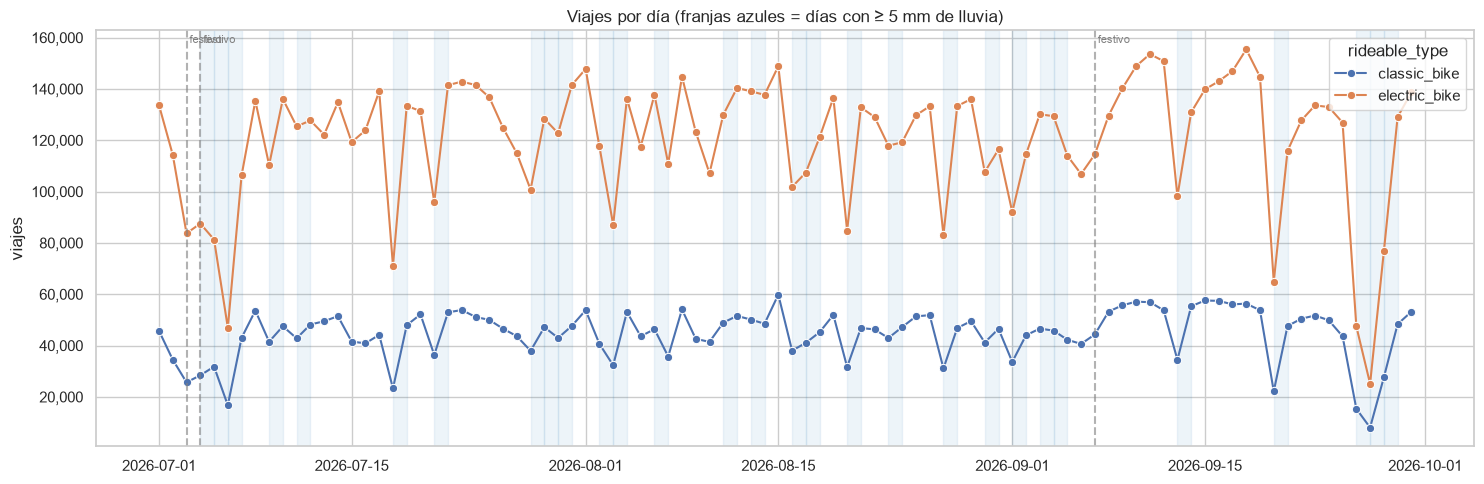

In [20]:
diario = (df.groupby([df['started_at'].dt.normalize().rename('fecha'), 'rideable_type'], observed=True)
            .size().rename('viajes').reset_index())
fig, ax = plt.subplots(figsize=(15, 5))
sns.lineplot(data=diario, x='fecha', y='viajes', hue='rideable_type', marker='o', ax=ax)
for f in [k for k in FESTIVOS if INICIO <= k < FIN]:
    ax.axvline(f, color='gray', ls='--', alpha=.6); ax.text(f, ax.get_ylim()[1] * .97, ' festivo', fontsize=8, color='gray')
lluvia_dia = slots.groupby('fecha')['precipitation'].sum() / 4
dias_lluvia = lluvia_dia[lluvia_dia >= 5].index
for f in dias_lluvia:
    ax.axvspan(f, f + pd.Timedelta(days=1), color='tab:blue', alpha=.08)
ax.set(title='Viajes por día (franjas azules = días con ≥ 5 mm de lluvia)', xlabel='', ylabel='viajes')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
plt.tight_layout(); plt.show()

### 9.2 Patrón semanal: día × hora (salidas de toda la ciudad)

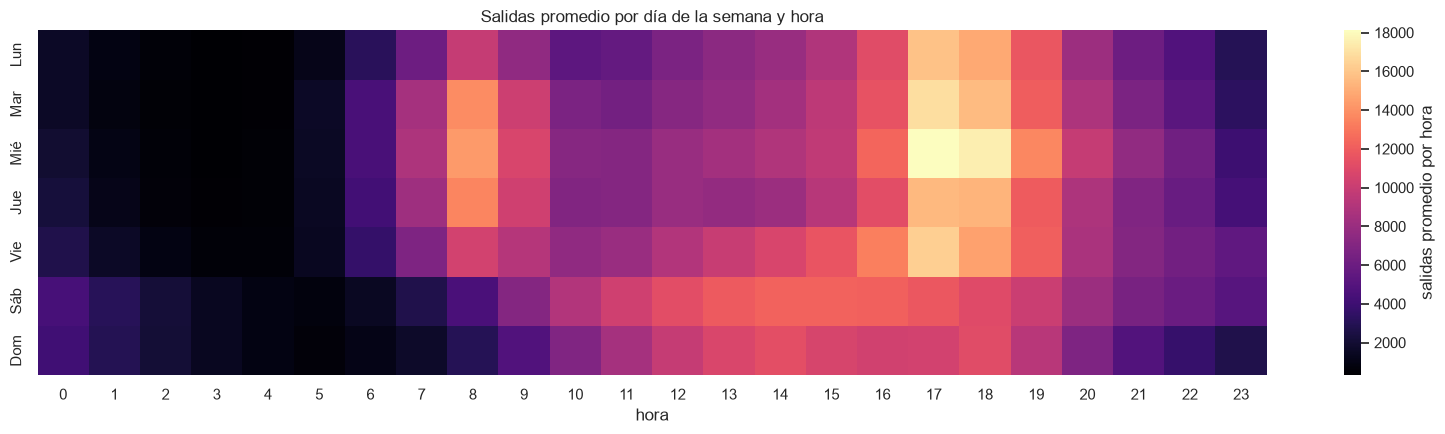

In [21]:
total_slot = Y.sum(axis=0)                 # [slot, 4] totales de la ciudad
ciudad = slots[['timestamp', 'fecha', 'hora', 'slot_dia', 'dia_semana', 'dia_libre', 'es_festivo'] + VARS_CLIMA + ['llueve']].copy()
for k, n in enumerate(TARGETS):
    ciudad[n] = total_slot[:, k]
ciudad['salidas'] = ciudad['salidas_classic'] + ciudad['salidas_electric']
ciudad['llegadas'] = ciudad['llegadas_classic'] + ciudad['llegadas_electric']

DIAS = ['Lun', 'Mar', 'Mié', 'Jue', 'Vie', 'Sáb', 'Dom']
n_dias = ciudad.groupby('dia_semana')['fecha'].nunique()
piv = ciudad.groupby(['dia_semana', 'hora'])['salidas'].sum().unstack() .div(n_dias, axis=0)
piv.index = DIAS
fig, ax = plt.subplots(figsize=(16, 4.5))
sns.heatmap(piv, cmap='magma', ax=ax, cbar_kws={'label': 'salidas promedio por hora'})
ax.set(title='Salidas promedio por día de la semana y hora', xlabel='hora', ylabel='')
plt.tight_layout(); plt.show()

### 9.3 Perfil de los 96 slots: laborable vs día libre

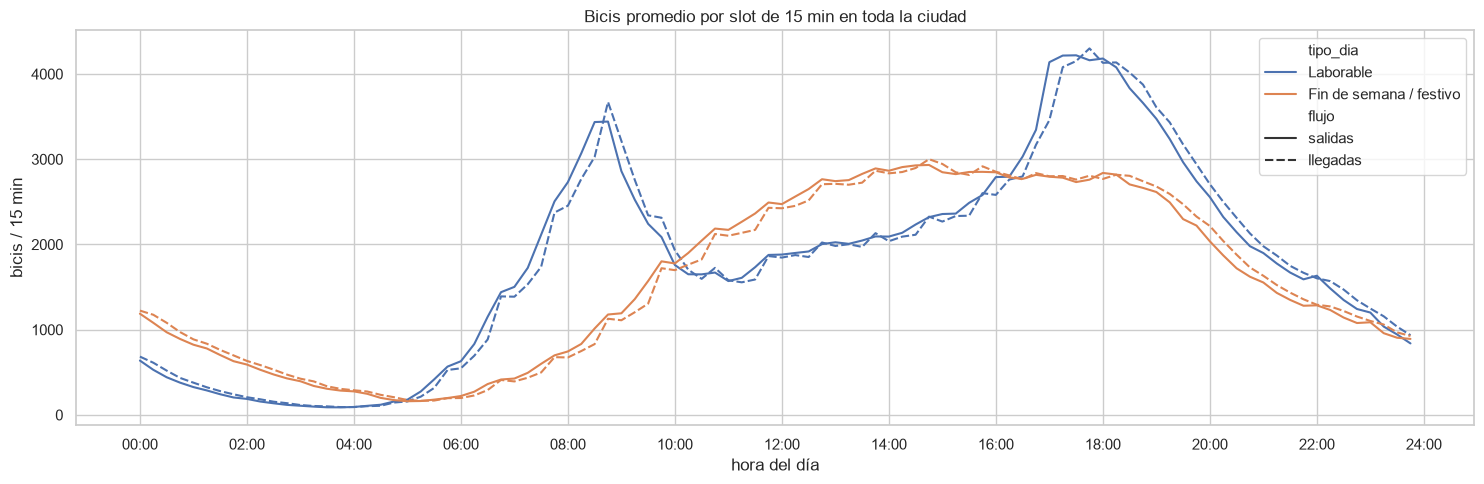

In [22]:
perfil = ciudad.groupby(['dia_libre', 'slot_dia'])[['salidas', 'llegadas']].mean().reset_index()
perfil['tipo_dia'] = perfil['dia_libre'].map({0: 'Laborable', 1: 'Fin de semana / festivo'})
perfil = perfil.melt(id_vars=['tipo_dia', 'slot_dia'], value_vars=['salidas', 'llegadas'], var_name='flujo', value_name='bicis')
fig, ax = plt.subplots(figsize=(15, 5))
sns.lineplot(data=perfil, x='slot_dia', y='bicis', hue='tipo_dia', style='flujo', ax=ax)
ax.set_xticks(range(0, 97, 8)); ax.set_xticklabels([f'{h:02d}:00' for h in range(0, 25, 2)])
ax.set(title='Bicis promedio por slot de 15 min en toda la ciudad', xlabel='hora del día', ylabel='bicis / 15 min')
plt.tight_layout(); plt.show()

### 9.4 Classic vs electric a lo largo del día

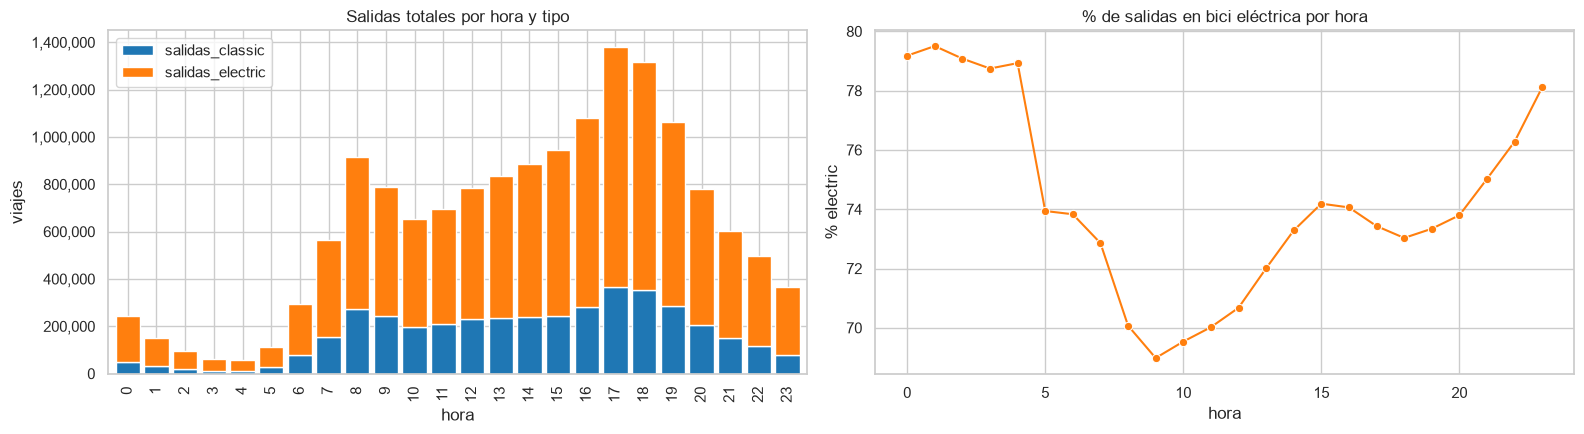

In [23]:
mix = ciudad.groupby('hora')[['salidas_classic', 'salidas_electric']].sum()
mix_pct = mix.div(mix.sum(axis=1), axis=0) * 100
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
mix.plot(kind='bar', stacked=True, ax=axes[0], color=['tab:blue', 'tab:orange'], width=.85)
axes[0].set(title='Salidas totales por hora y tipo', xlabel='hora', ylabel='viajes')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
sns.lineplot(x=mix_pct.index, y=mix_pct['salidas_electric'], marker='o', ax=axes[1], color='tab:orange')
axes[1].set(title='% de salidas en bici eléctrica por hora', xlabel='hora', ylabel='% electric')
plt.tight_layout(); plt.show()

### 9.5 Estaciones con más movimiento

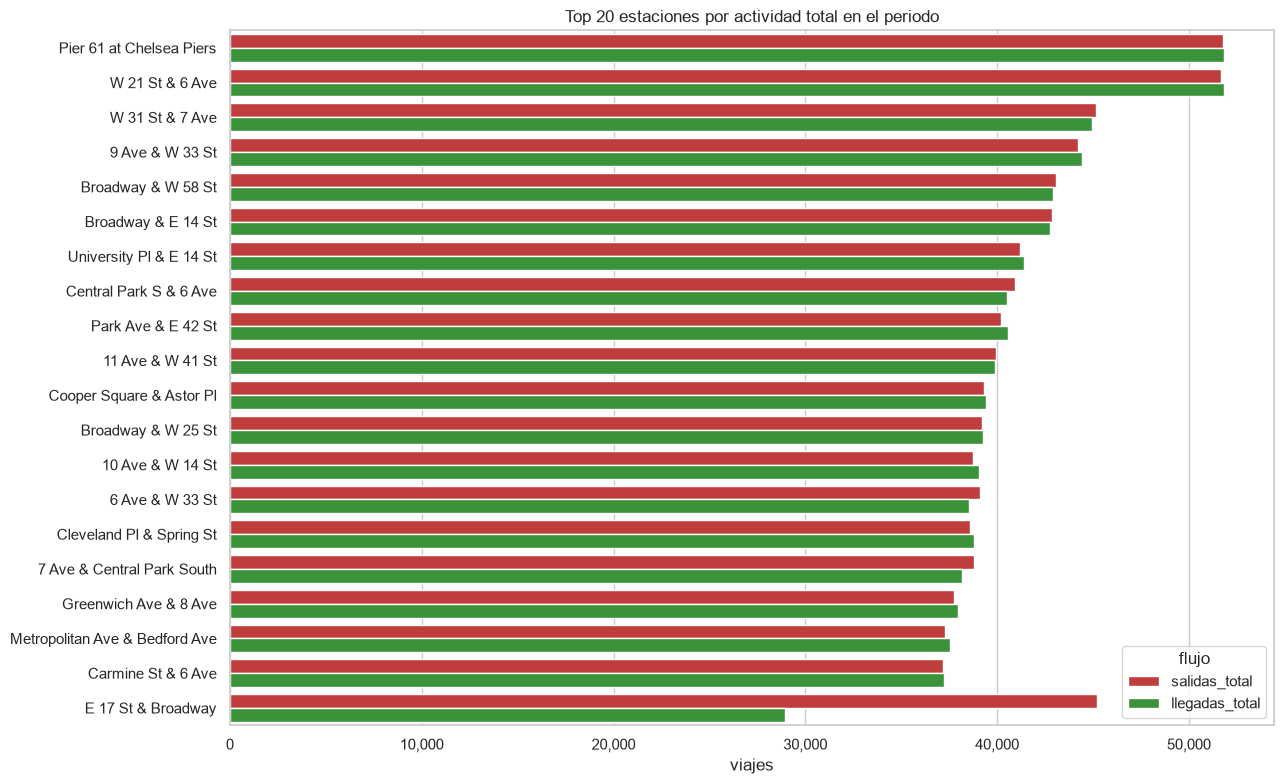

In [24]:
top = estaciones.head(20).copy()
top['nombre'] = top['name'].str.slice(0, 38)
top_m = top.melt(id_vars='nombre', value_vars=['salidas_total', 'llegadas_total'], var_name='flujo', value_name='viajes')
fig, ax = plt.subplots(figsize=(13, 8))
sns.barplot(data=top_m, y='nombre', x='viajes', hue='flujo', ax=ax, palette=['tab:red', 'tab:green'])
ax.set(title='Top 20 estaciones por actividad total en el periodo', ylabel='', xlabel='viajes')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
plt.tight_layout(); plt.show()

### 9.6 Flujo neto: ¿qué estaciones se vacían y cuáles se llenan?
Flujo neto = llegadas − salidas. **Rojo** significa que la estación se vacía (salen más bicis de las que llegan) y **azul** que se llena. Se compara la hora pico de la mañana con la de la tarde en días laborables. Es la vista más directa del problema de inventario.

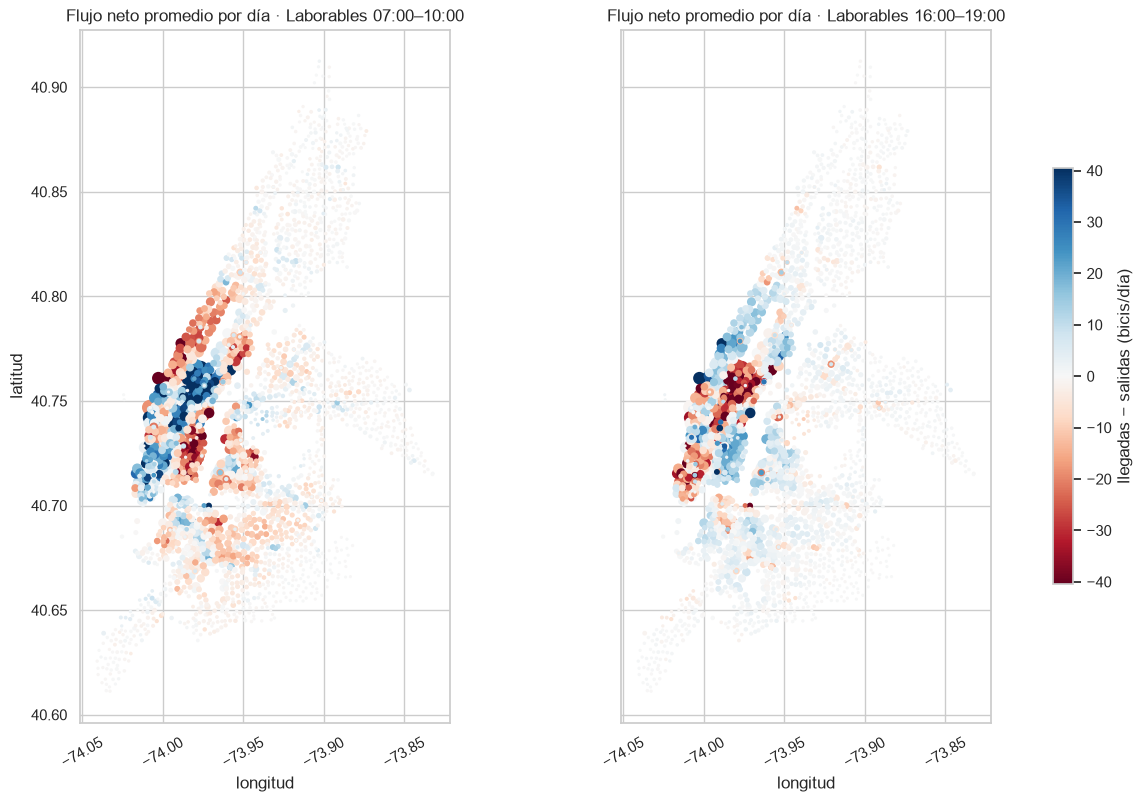

🔴 Más se vacían en la mañana:


,name,neto_am,neto_pm,actividad_total
38,W 43 St & 10 Ave,-68.3,48.2,64390
71,E 10 St & Ave A,-62.8,35.8,51595
99,Riverside Blvd & W 67 St,-58.2,40.4,47383
103,FDR Drive & E 35 St,-55.2,71.0,46969
119,W 44 St & 11 Ave,-55.2,34.1,44696
96,E 2 St & Ave B,-52.0,24.2,47848
361,E 6 St & Ave B,-51.9,21.0,28312
386,Grand St & Samuel Dickstein Plaza,-49.9,23.2,26941


🔵 Más se llenan en la mañana:


,name,neto_am,neto_pm,actividad_total
3,9 Ave & W 33 St,124.6,-118.5,88643
169,E 47 St & Park Ave,99.1,-103.5,39984
11,Broadway & W 25 St,80.1,-69.6,78486
710,Dock 72 Way & Market St,79.7,-72.3,14265
76,Greenwich St & W Houston St,75.6,-38.2,50716
263,E 40 St & Park Ave,72.5,-67.4,33254
69,Broadway & E 19 St,72.1,-48.0,52003
93,E 40 St & 5 Ave,70.0,-62.4,47907


In [25]:
laborable = (slots['dia_libre'] == 0).values
n_lab = slots.loc[laborable, 'fecha'].nunique()
def neto_ventana(h_ini, h_fin):
    m = laborable & slots['hora'].between(h_ini, h_fin - 1).values
    lle = Y[:, m, 2:].sum(axis=(1, 2)); sal = Y[:, m, :2].sum(axis=(1, 2))
    return (lle - sal) / max(n_lab, 1)

estaciones['neto_am'] = neto_ventana(7, 10)
estaciones['neto_pm'] = neto_ventana(16, 19)
lim = np.nanpercentile(np.abs(estaciones[['neto_am', 'neto_pm']].values), 98)

fig, axes = plt.subplots(1, 2, figsize=(16, 9), sharex=True, sharey=True)
for ax, col, tit in zip(axes, ['neto_am', 'neto_pm'], ['Laborables 07:00–10:00', 'Laborables 16:00–19:00']):
    sns.scatterplot(data=estaciones, x='lng', y='lat', hue=col, palette='RdBu', hue_norm=(-lim, lim),
                    size='actividad_total', sizes=(5, 120), ax=ax, legend=False, edgecolor='none')
    ax.set(title=f'Flujo neto promedio por día · {tit}', xlabel='longitud', ylabel='latitud'); ax.set_aspect(1.3)
    ax.tick_params(axis='x', rotation=30)
sm = plt.cm.ScalarMappable(cmap='RdBu', norm=plt.Normalize(-lim, lim))
fig.colorbar(sm, ax=axes, shrink=.6, label='llegadas − salidas (bicis/día)')
plt.show()

cols = ['name', 'neto_am', 'neto_pm', 'actividad_total']
print('🔴 Más se vacían en la mañana:'); display(estaciones.nsmallest(8, 'neto_am')[cols].round(1))
print('🔵 Más se llenan en la mañana:'); display(estaciones.nlargest(8, 'neto_am')[cols].round(1))

### 9.7 Mapa de densidad de demanda

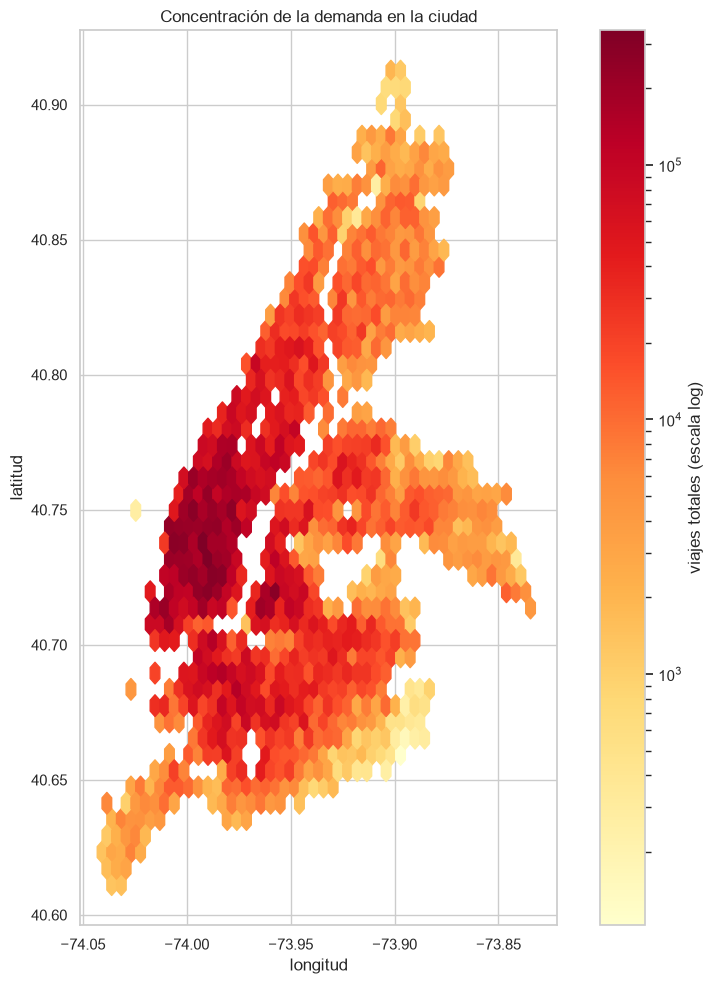

In [26]:
fig, ax = plt.subplots(figsize=(9, 10))
hb = ax.hexbin(estaciones['lng'], estaciones['lat'], C=estaciones['actividad_total'],
               reduce_C_function=np.sum, gridsize=45, cmap='YlOrRd', bins='log', mincnt=1)
fig.colorbar(hb, ax=ax, label='viajes totales (escala log)')
ax.set(title='Concentración de la demanda en la ciudad', xlabel='longitud', ylabel='latitud'); ax.set_aspect(1.3)
plt.tight_layout(); plt.show()

### 9.8 Impacto del clima

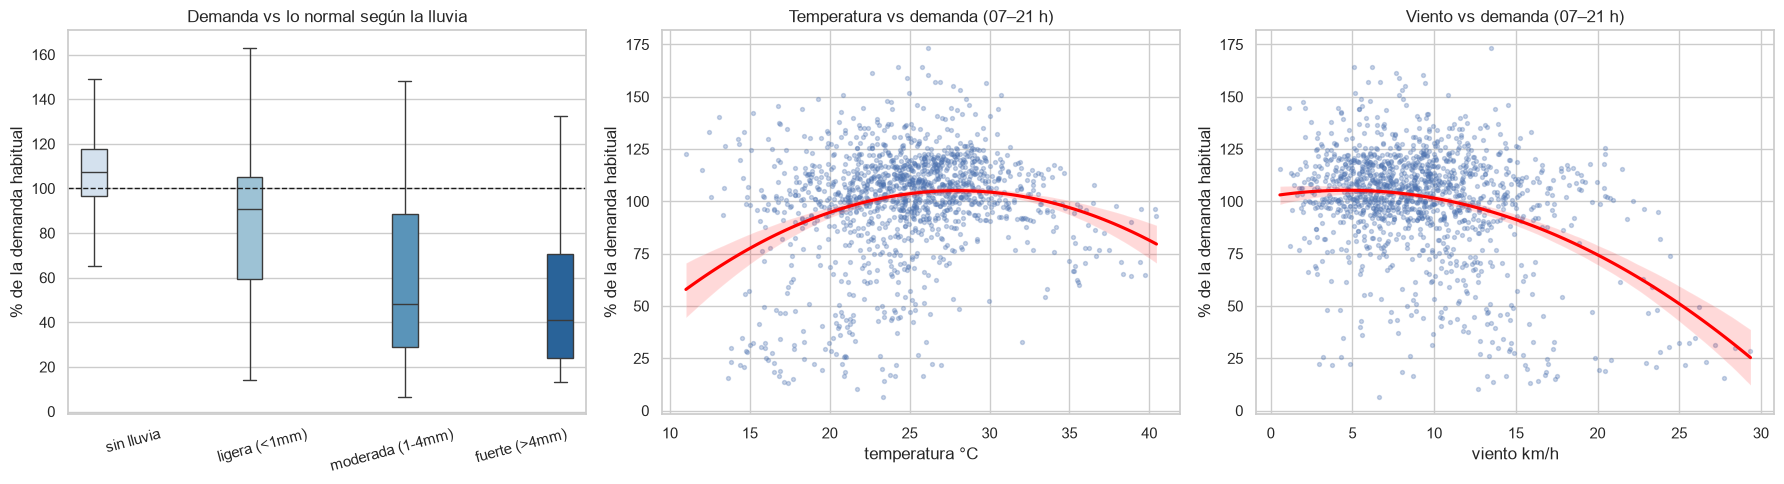

In [27]:
horario = ciudad.groupby(ciudad['timestamp'].dt.floor('h')).agg(
    salidas=('salidas', 'sum'), temperature_2m=('temperature_2m', 'mean'), precipitation=('precipitation', 'mean'),
    wind_speed_10m=('wind_speed_10m', 'mean'), hora=('hora', 'first'), dia_libre=('dia_libre', 'first'))
horario['lluvia'] = pd.cut(horario['precipitation'], [-0.01, 0.09, 1, 4, 1000],
                           labels=['sin lluvia', 'ligera (<1mm)', 'moderada (1-4mm)', 'fuerte (>4mm)'])
# para aislar el efecto del clima se compara contra el promedio de esa misma hora y tipo de día
base = horario.groupby(['hora', 'dia_libre'])['salidas'].transform('mean')
horario['vs_normal'] = horario['salidas'] / base * 100

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.boxplot(data=horario, x='lluvia', y='vs_normal', ax=axes[0], palette='Blues', hue='lluvia', legend=False, showfliers=False)
axes[0].axhline(100, color='k', ls='--', lw=1)
axes[0].set(title='Demanda vs lo normal según la lluvia', xlabel='', ylabel='% de la demanda habitual')
axes[0].tick_params(axis='x', rotation=15)
sns.regplot(data=horario[horario.hora.between(7, 21)], x='temperature_2m', y='vs_normal', ax=axes[1],
            scatter_kws=dict(s=8, alpha=.3), line_kws=dict(color='red'), order=2)
axes[1].set(title='Temperatura vs demanda (07–21 h)', xlabel='temperatura °C', ylabel='% de la demanda habitual')
sns.regplot(data=horario[horario.hora.between(7, 21)], x='wind_speed_10m', y='vs_normal', ax=axes[2],
            scatter_kws=dict(s=8, alpha=.3), line_kws=dict(color='red'), order=2)
axes[2].set(title='Viento vs demanda (07–21 h)', xlabel='viento km/h', ylabel='% de la demanda habitual')
plt.tight_layout(); plt.show()

### 9.9 Correlaciones
Se calculan sobre los totales de la ciudad por slot. Los objetivos se comparan contra el calendario y el clima. Ojo: la hora tiene una relación **no lineal** con la demanda (dos picos), por eso su correlación lineal es baja aunque sea la variable más importante. De ahí que en el modelo se codifique como embedding y con seno/coseno.

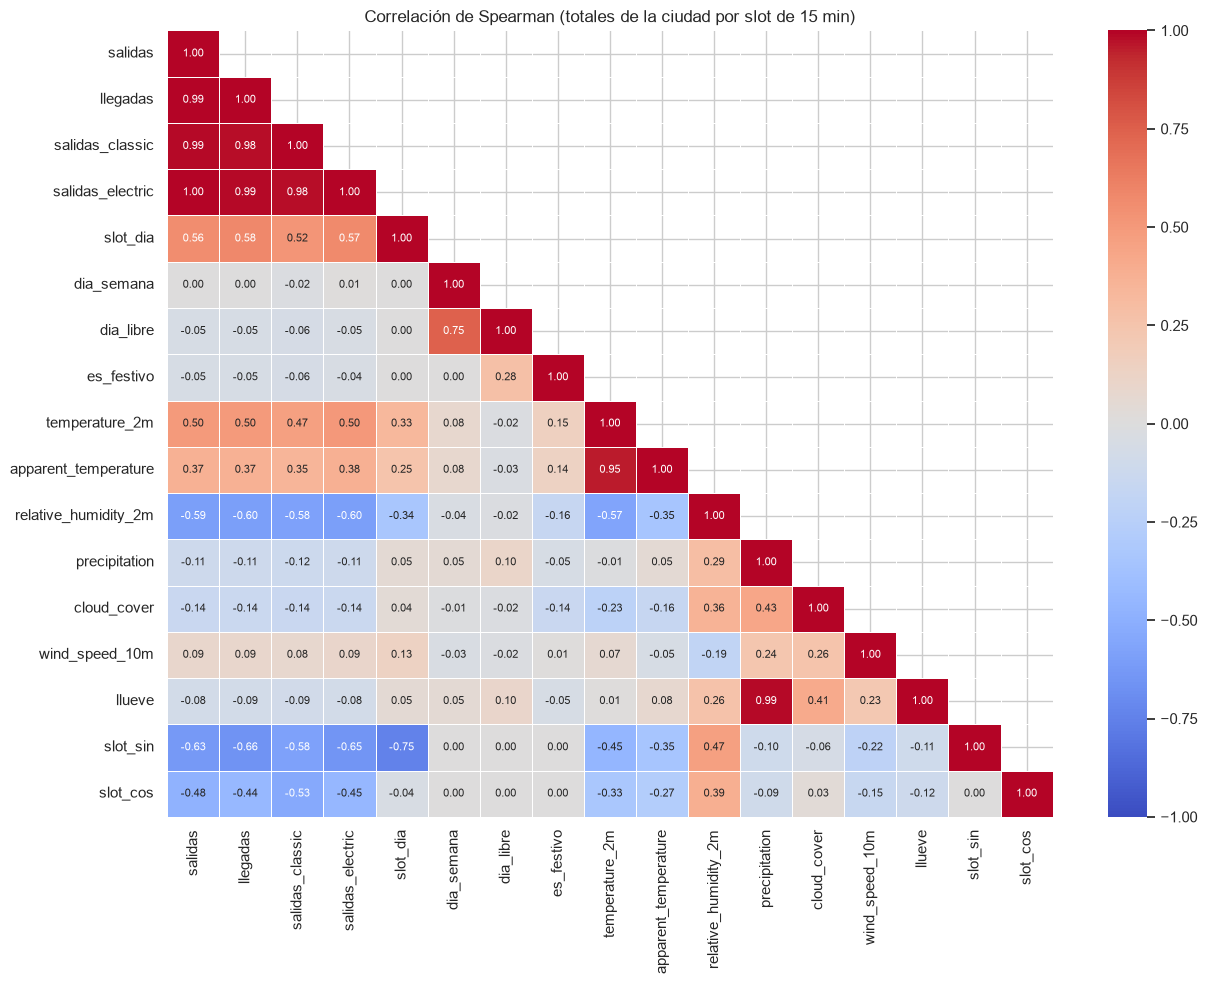

In [28]:
corr_cols = ['salidas', 'llegadas', 'salidas_classic', 'salidas_electric', 'slot_dia', 'dia_semana', 'dia_libre',
             'es_festivo', 'temperature_2m', 'apparent_temperature', 'relative_humidity_2m', 'precipitation',
             'cloud_cover', 'wind_speed_10m', 'llueve']
c_df = ciudad.assign(slot_sin=slots['slot_sin'], slot_cos=slots['slot_cos'])
corr = c_df[corr_cols + ['slot_sin', 'slot_cos']].corr(method='spearman')
fig, ax = plt.subplots(figsize=(13, 10))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1,
            ax=ax, annot_kws={'size': 8}, linewidths=.5)
ax.set_title('Correlación de Spearman (totales de la ciudad por slot de 15 min)')
plt.tight_layout(); plt.show()

### 9.10 Distribución de los conteos por estación y slot
Justifica la **Poisson loss**: la gran mayoría de los slots tienen 0, 1 o 2 bicis y la distribución es muy asimétrica.

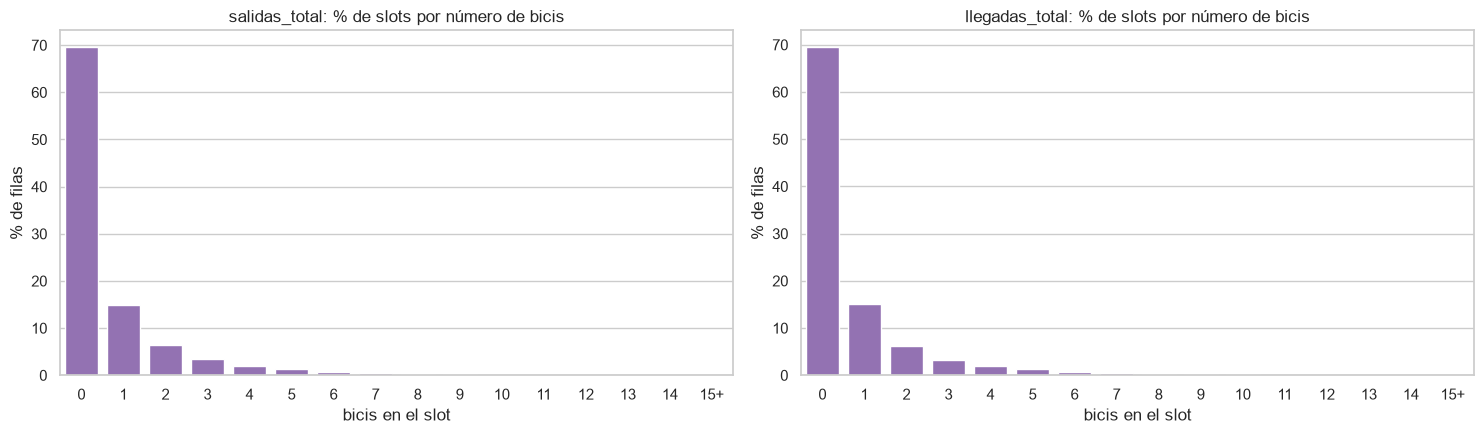

salidas_total → media=0.727, varianza=2.799 (varianza > media indica sobre-dispersión)


In [29]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, col in zip(axes, ['salidas_total', 'llegadas_total']):
    vc = demanda[col].clip(upper=15).value_counts(normalize=True).sort_index() * 100
    sns.barplot(x=vc.index.astype(str).str.replace('15', '15+'), y=vc.values, ax=ax, color='tab:purple')
    ax.set(title=f'{col}: % de slots por número de bicis', xlabel='bicis en el slot', ylabel='% de filas')
plt.tight_layout(); plt.show()

media, var = demanda['salidas_total'].mean(), demanda['salidas_total'].var()
print(f'salidas_total → media={media:.3f}, varianza={var:.3f} (varianza > media indica sobre-dispersión)')

### 9.11 Member vs casual (sólo contexto, no entra al modelo)

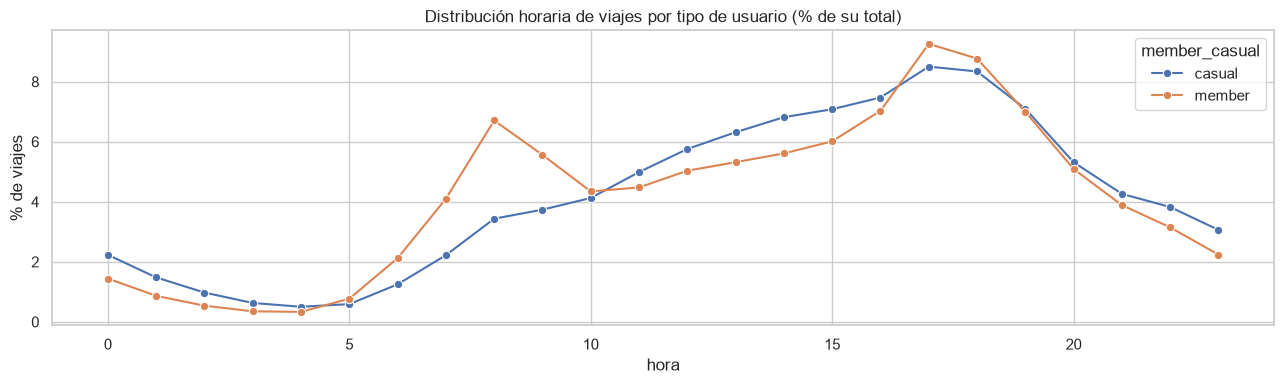

{'member': 0.798, 'casual': 0.202}


In [30]:
mc = (df.groupby([df['started_at'].dt.hour.rename('hora'), 'member_casual'], observed=True).size()
        .rename('viajes').reset_index())
mc['pct'] = mc['viajes'] / mc.groupby('member_casual', observed=True)['viajes'].transform('sum') * 100
fig, ax = plt.subplots(figsize=(13, 4))
sns.lineplot(data=mc, x='hora', y='pct', hue='member_casual', marker='o', ax=ax)
ax.set(title='Distribución horaria de viajes por tipo de usuario (% de su total)', ylabel='% de viajes')
plt.tight_layout(); plt.show()
print(df['member_casual'].value_counts(normalize=True).round(3).to_dict())

## 10. Resumen de la limpieza

,paso,filas,eliminadas,% del original
0,Original (todas las filas),15222228,0,100.00
1,Sin nulls ni vacíos,15170092,52136,99.66
2,Sin ride_id duplicados,15170092,0,99.66
3,Sólo classic_bike / electric_bike,15170092,0,99.66
4,ended_at > started_at,15170092,0,99.66
5,Duración ≤ 24 h,15170092,0,99.66
6,Coordenadas dentro de NYC,15170092,0,99.66
7,Sin estaciones de prueba / taller,15170092,0,99.66
8,Inicio dentro del periodo,15169280,812,99.65


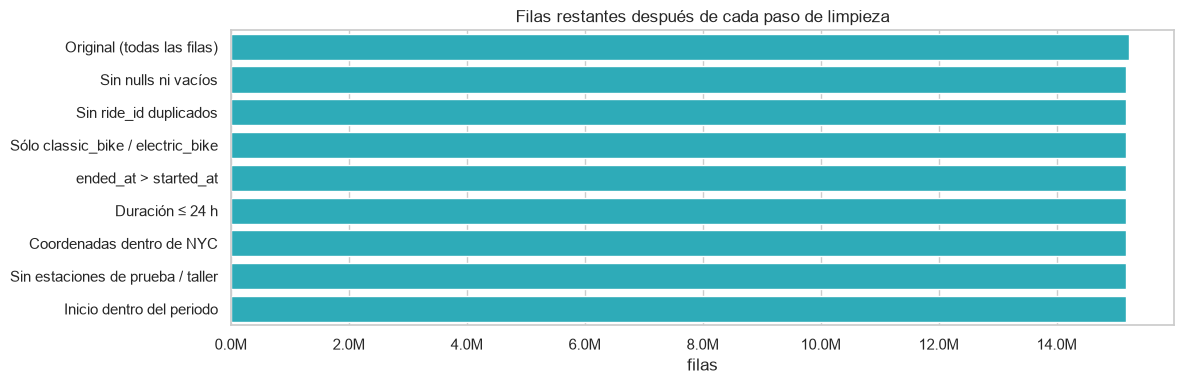

In [31]:
bit = pd.DataFrame(bitacora, columns=['paso', 'filas'])
bit['eliminadas'] = (-bit['filas'].diff()).fillna(0).astype(int)
bit['% del original'] = (bit['filas'] / FILAS_ORIGINALES * 100).round(2)
display(bit)

fig, ax = plt.subplots(figsize=(12, 4))
sns.barplot(data=bit, y='paso', x='filas', ax=ax, color='tab:cyan')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x / 1e6:.1f}M'))
ax.set(title='Filas restantes después de cada paso de limpieza', ylabel='', xlabel='filas')
plt.tight_layout(); plt.show()

## 11. Exportar los datos para el notebook 02

In [32]:
est_out = estaciones[['station_idx', 'station_id', 'name', 'lat', 'lng', 'salidas_total', 'llegadas_total',
                      'actividad_total', 'primer_dia', 'ultimo_dia', 'dias_activa', 'neto_am', 'neto_pm']]
est_out.to_parquet(OUT_DIR / 'estaciones.parquet', index=False)
slots.to_parquet(OUT_DIR / 'slots.parquet', index=False)
demanda.to_parquet(OUT_DIR / 'demanda_15min.parquet', index=False)

meta = dict(inicio=str(INICIO), fin=str(FIN), freq=FREQ, n_estaciones=int(N_EST), n_slots=int(N_SLOTS),
            filas_demanda=int(len(demanda)), targets=TARGETS, vars_clima=VARS_CLIMA,
            min_viajes_estacion=MIN_VIAJES_ESTACION, lat=NYC_LAT, lon=NYC_LON, tz=TZ)
pd.Series(meta).to_json(OUT_DIR / 'metadata.json', indent=2)

for f in sorted(OUT_DIR.iterdir()):
    print(f'{f.name:<30} {f.stat().st_size / 1e6:8.1f} MB')
print(f'\n✅ Listo: {N_EST:,} estaciones × {N_SLOTS:,} slots → {len(demanda):,} filas para el modelo')

clima_horario_raw.parquet           0.0 MB
demanda_15min.parquet              72.2 MB
estaciones.parquet                  0.2 MB
metadata.json                       0.0 MB
slots.parquet                       0.2 MB

✅ Listo: 2,461 estaciones × 8,832 slots → 20,865,600 filas para el modelo
